## Generate cell population data for figure 3 for all six conditions

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
from pathlib import Path
import datetime
import pickle
sys.path.insert(0, "./cellular_cycle")
sys.path.insert(0, "./figures")

from cell_cycle_death_model import model
from pysb.simulator import BngSimulator
from pysb.simulator import ScipyOdeSimulator
from model_fxns import *
from Cell_Population_Simulation import Cell_Population_Simulation
from SMs_G1s_IMTs_extraction import SMs_G1s_IMTs_extraction

In [2]:
# Where to save large simulation output files
SAVE_DIR = Path(Path.home(),'ECM_mod_output')
if not SAVE_DIR.exists():
    SAVE_DIR.mkdir()

OVERWRITE = False # Overwrite existing simulation files

CURDATE = datetime.datetime.now().strftime('%Y%m%d')

In [3]:
# import pysb sampled parameters
sampled_parameter_names = np.loadtxt(os.getcwd() + '/model_data/sampled_parameter_names.txt', dtype=str)

In [4]:
# Importing the parameters:
new_param = pd.read_csv(os.getcwd()+ '/test_treatments/parameters.csv')
for key in new_param.keys():
    try:
        if model.parameters[key].value != new_param[key][0]:
            model.parameters[key].value = new_param[key]
    except:
        print(key)
model.parameters['omega'].value = 200

Stress
b
Hippo_tot
Yap_tot
AKT_tot
ERK_tot
FAK_tot
skp2_tot
p21_tot
cdh1_tot
CycD_tot
K_1E2F
V_1E2F
k_cd4
k_myc1
k_CE
d_CE
K_i13
K_i14
V_sac
V_da
V_sec
V_de
V_sf
V_fs
V_dfa
v_scdh1a
v_2fak
v_s2p21
K_AFAK
K_dfa
K_fs
K_cf
K_cac
K_cec
K_da
K_de
K_sp21
k_dcdh1a
K_p21fak.1
k_CDF
K_DF
K_dcescp2


In [5]:
# Setting initial concentrations '/../model_data/initial_concentrations.csv'
initial_concentrations = pd.read_csv(os.getcwd() + '/model_data/initial_concentrations.csv')
for key in initial_concentrations.keys():
    try:
        model.parameters[key].value = initial_concentrations[key][0] / model.parameters['omega'].value
    except:
        print(key)

BAXm_0
BCL2_0


In [6]:
# Import ECM_conditions.csv
ECM_conditions = pd.read_csv(os.getcwd() + '/model_data/ECM_conditions_2.csv')
ECM_conditions


,condition,stiffness,drug,species,value
0,55 kPa DMSO,55 kPa,DMSO,AKT,1.0
1,55 kPa DMSO,55 kPa,DMSO,ERK,1.0
2,55 kPa DMSO,55 kPa,DMSO,FAK,1.0
3,4 kPa DMSO,4 kPa,DMSO,AKT,1.0
4,4 kPa DMSO,4 kPa,DMSO,ERK,1.0
5,4 kPa DMSO,4 kPa,DMSO,FAK,0.6
6,0.6 kPa DMSO,0.6 kPa,DMSO,AKT,0.6
7,0.6 kPa DMSO,0.6 kPa,DMSO,ERK,1.0
8,0.6 kPa DMSO,0.6 kPa,DMSO,FAK,0.4
9,55 kPa erlotinib,55 kPa,erlotinib,AKT,0.6


<Axes: xlabel='Time (h)', ylabel='Concentration'>

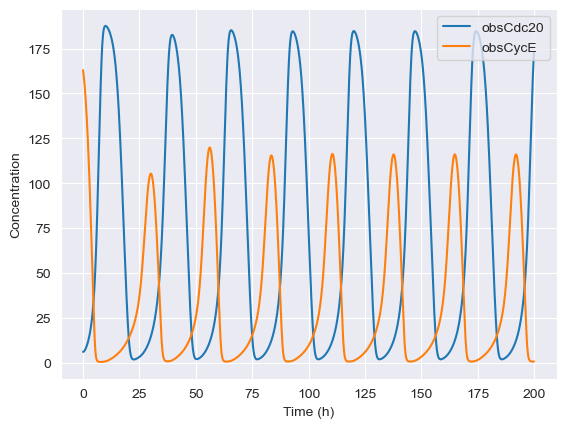

In [7]:
condition = "55 kPa erlotinib"

t = np.linspace(0, 20000, 200001)

model.parameters['AKT'].value = 0.6
model.parameters['ERK'].value = 0.2
model.parameters['FAK'].value = 1
# t = np.linspace(0, 50000, 500001)
sim_ode = ScipyOdeSimulator(model, t, verbose=False, compiler='python').run() #deterministic simulation

observables=['obsCdc20', 'obsCycE']
plotObs(model=sim_ode.all, obs=observables, times=t, tpos=range(0,2000), legend=True)


<Axes: xlabel='Time (h)', ylabel='Concentration'>

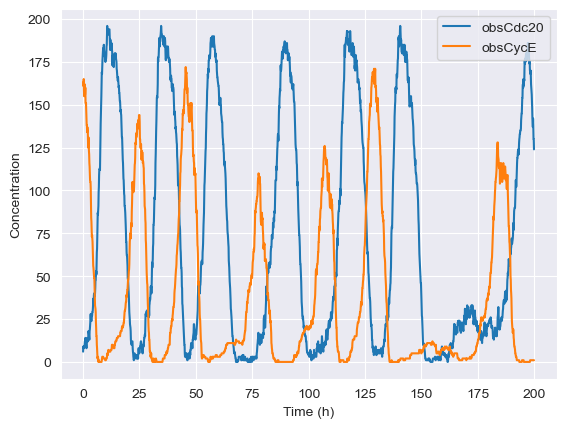

In [8]:
sim_stoch = BngSimulator(model, tspan=t, verbose=False)
sim_stoch_res = sim_stoch.run(method='ssa', verbose=False)
observables=['obsCdc20', 'obsCycE']
plotObs(model=sim_stoch_res.all, obs=observables, times=t, tpos=range(0,2000), legend=True)


### Run example simulation
Use low stiffness and DMSO treatment as condition. Must use more cells to get decent output.

In [10]:
start_time = datetime.datetime.now()

init = 3
run_time = 120
observed_cells_time = 120
condition = "55 kPa erlotinib"

In [10]:
# Run the model
# Simulate Check_Model_Consistency
# (variable_range, check, tmp_score) = Check_Model_Consistency(model, thr=0.26, return_plot=True)

(check, population_df, cells, cell_count) = Cell_Population_Simulation(init, run_time, observed_cells_time, model, ECM_conditions, condition, sampled_parameter_names, thr=[0.26, 0.14], return_plot=False, bypass=True)
current_time = datetime.datetime.now()
print(f'elapsed time is {(current_time-start_time)/60} minutes')

55 kPa erlotinib
BAXm_0
BCL2_0
elapsed time is 0:00:01.102011 minutes


In [12]:
import fracprolif as fp

In [11]:
population_history = population_df
parameters_sim = {}

In [13]:
population_df

,Old ID,New ID,Lineage,Event,Start Time,Birth Time,End Time,Starting Cell,Lifetime
0,0,0,Initial cell,Mitosis,0.000000,Initial cell,12.541806,True,12.541806
1,0,61,0,Mitosis,12.541806,12.541806,38.929766,False,26.387960
2,0,62,61,Mitosis,38.929766,38.929766,60.000000,False,21.070234
3,0,63,62,Mitosis,60.000000,60.0,105.752508,False,45.752508
4,0,64,63,Mitosis,105.752508,105.752508,119.297659,False,13.545151
...,...,...,...,...,...,...,...,...,...
114,56,56,35,End of experiment,101.839465,101.839465,120.092396,False,18.252931
115,57,57,36,End of experiment,110.769231,110.769231,120.088347,False,9.319117
116,58,58,40,End of experiment,112.173913,112.173913,120.086957,False,7.913043
117,59,59,44,End of experiment,93.010033,93.010033,120.093850,False,27.083817


### New plotting function
Use seaborn and pandas. Should also save output files as csv (or parquet or feather) to maximize cross compatibility. Simple save procedure once data are in pandas DataFrame.  

In [14]:
model.parameters['CycDi_0'].value

0.0

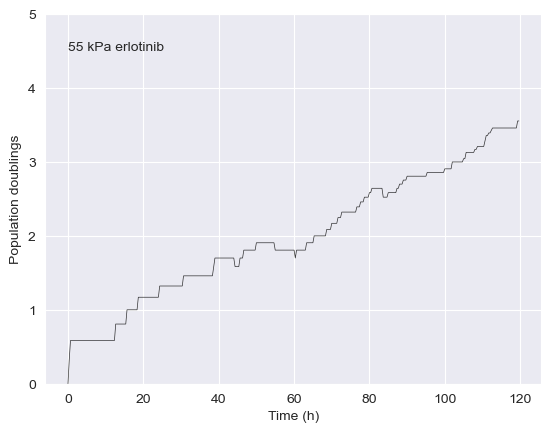

In [15]:
fig, ax = make_fig(cell_count, run_time, title=condition)
add_plot(cell_count, run_time, fig, ax, title=condition)

In [16]:
from call_cell_events import call_events #
from retrieve_cellState_dw_2 import retrieve_cellState #

  Starting cell End_of_Expt  Death   Birthtime   Lifespan
0          True       False  False           0  12.541806
1         False       False  False   12.541806  26.387960
2         False       False  False   38.929766  22.374582
3         False       False  False   61.304348  44.448161
4         False       False  False  105.752508  13.545151
5         False        True  False  119.297659   0.602007
{'Starting cell': True, 'End_of_Expt': False, 'Death': False, 'Birthtime': 0, 'Lifespan': 0.6020066889632}
  Starting cell End_of_Expt  Death   Birthtime   Lifespan
0          True       False  False           0  12.541806
1         False       False  False   12.541806  26.387960
2         False       False  False   38.929766  22.374582
3         False       False  False   61.304348  44.448161
4         False       False  False  105.752508  13.545151
5         False        True  False  119.297659   0.602007
6          True       False  False           0   0.602007
7         False       F

(0.0, 125.0)

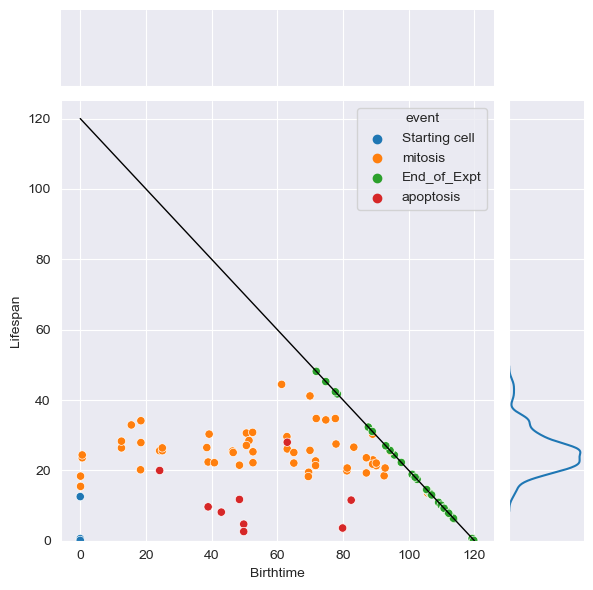

In [17]:
IMT_eoe_counts, all_prot = retrieve_cellState(run_time, cells, return_all_prot=True)
all_events_simulated = call_events(run_time, IMT_eoe_counts) #Gives all events (apoptosis, mitosis, quiescence) and when they happen

#plot the results
grid = sns.JointGrid(x='Birthtime', y='Lifespan', data=all_events_simulated) #x axis = birthtime of a cell, y = endtime of this cell
g = grid.plot_joint(sns.scatterplot, hue='event', data=all_events_simulated) 
g.ax_joint.plot([run_time, 0], [0, run_time], 'b-', linewidth = 1, color='black') #Recorded events behind this line
sns.kdeplot(all_events_simulated.loc[all_events_simulated['event']=='mitosis', 'Lifespan'].to_list(), 
            ax=g.ax_marg_y, vertical=True, legend=False, bw=0.3) #output distribution of intermitotic times
plt.ylim(0, 125)

In [18]:
all_events_simulated

,event,Birthtime,Lifespan
0,Starting cell,0,12.541806
1,mitosis,12.541806,26.387960
2,mitosis,38.929766,22.374582
3,mitosis,61.304348,44.448161
4,mitosis,105.752508,13.545151
...,...,...,...
113,End_of_Expt,106.982556,13.008995
114,End_of_Expt,110.769231,9.217822
115,End_of_Expt,112.173913,7.811594
116,End_of_Expt,93.010033,26.983133


  Starting cell End_of_Expt  Death   Birthtime   Lifespan
0          True       False  False           0  12.541806
1         False       False  False   12.541806  26.387960
2         False       False  False   38.929766  22.374582
3         False       False  False   61.304348  44.448161
4         False       False  False  105.752508  13.545151
5         False        True  False  119.297659   0.602007
{'Starting cell': True, 'End_of_Expt': False, 'Death': False, 'Birthtime': 0, 'Lifespan': 0.6020066889632}
  Starting cell End_of_Expt  Death   Birthtime   Lifespan
0          True       False  False           0  12.541806
1         False       False  False   12.541806  26.387960
2         False       False  False   38.929766  22.374582
3         False       False  False   61.304348  44.448161
4         False       False  False  105.752508  13.545151
5         False        True  False  119.297659   0.602007
6          True       False  False           0   0.602007
7         False       F

(0.0, 125.0)

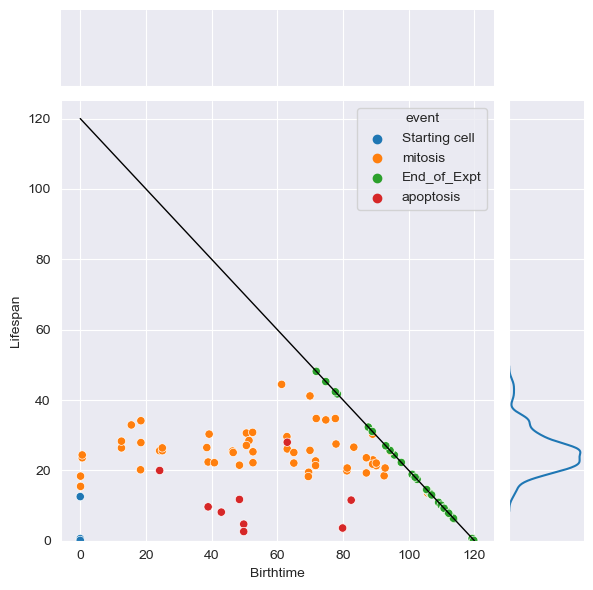

In [19]:
IMT_eoe_counts, all_prot = retrieve_cellState(run_time, cells, return_all_prot=True)
all_events_simulated = call_events(run_time, IMT_eoe_counts) #Gives all events (apoptosis, mitosis, quiescence) and when they happen

#plot the results
grid = sns.JointGrid(x='Birthtime', y='Lifespan', data=all_events_simulated) #x axis = birthtime of a cell, y = endtime of this cell
g = grid.plot_joint(sns.scatterplot, hue='event', data=all_events_simulated) 
g.ax_joint.plot([run_time, 0], [0, run_time], 'b-', linewidth = 1, color='black') #Recorded events behind this line
sns.kdeplot(all_events_simulated.loc[all_events_simulated['event']=='mitosis', 'Lifespan'].to_list(), 
            ax=g.ax_marg_y, vertical=True, legend=False, bw=0.3) #output distribution of intermitotic times
plt.ylim(0, 125)

In [22]:
params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

In [24]:
start_time = datetime.datetime.now()

conditions = ['4 kPa erlotinib', '4 kPa DMSO', '55 kPa erlotinib', '55 kPa DMSO']


for condition in conditions:
    for num in range(3):
        init = 5
        
        (check, population_df, cells, cell_count) = Cell_Population_Simulation(init, run_time, observed_cells_time, model, ECM_conditions, condition, sampled_parameter_names, thr=[0.26, 0.14], return_plot=False, bypass=True)
        
        filename = Path(SAVE_DIR, f'cells_{condition}_{num}_param_orig.csv')
        if OVERWRITE or not os.path.exists(filename):
            print(f"Saving to {filename}...")
            with open(filename, 'wb') as f:
                pickle.dump(cells, f, protocol=pickle.HIGHEST_PROTOCOL)
        else:
            print(f"File {filename} already exists. Skipping...")
            
        filename = Path(SAVE_DIR, f'cellcount_{condition}_{num}_orig_param_orig.csv')
        if OVERWRITE or not os.path.exists(filename):
            print(f"Saving to {filename}...")
            np.savetxt(filename, cell_count, delimiter=',')
        else:
            print(f"File {filename} already exists. Skipping...")
        current_time = datetime.datetime.now()
        print(f'elapsed time is {(current_time-start_time)/60} minutes')

4 kPa erlotinib
BAXm_0
BCL2_0
File C:\Users\olesk\ECM_mod_output\cells_4 kPa erlotinib_0_param_orig.csv already exists. Skipping...
Saving to C:\Users\olesk\ECM_mod_output\cellcount_4 kPa erlotinib_0_orig_param_orig.csv...
elapsed time is 0:00:00.925606 minutes
4 kPa erlotinib
BAXm_0
BCL2_0
File C:\Users\olesk\ECM_mod_output\cells_4 kPa erlotinib_1_param_orig.csv already exists. Skipping...
Saving to C:\Users\olesk\ECM_mod_output\cellcount_4 kPa erlotinib_1_orig_param_orig.csv...
elapsed time is 0:00:01.772399 minutes
4 kPa erlotinib
BAXm_0
BCL2_0
File C:\Users\olesk\ECM_mod_output\cells_4 kPa erlotinib_2_param_orig.csv already exists. Skipping...
Saving to C:\Users\olesk\ECM_mod_output\cellcount_4 kPa erlotinib_2_orig_param_orig.csv...
elapsed time is 0:00:03.145085 minutes
4 kPa DMSO
BAXm_0
BCL2_0
File C:\Users\olesk\ECM_mod_output\cells_4 kPa DMSO_0_param_orig.csv already exists. Skipping...
Saving to C:\Users\olesk\ECM_mod_output\cellcount_4 kPa DMSO_0_orig_param_orig.csv...
elapse

In [ ]:
conditions = ['0.6 kPa erlotinib', '0.6 kPa DMSO']

for condition in conditions:
    for num in range(3):
        init = 10
        
        (check, population_df, cells, cell_count) = Cell_Population_Simulation(init, run_time, observed_cells_time, model, ECM_conditions, condition, sampled_parameter_names, thr=[0.26, 0.14], return_plot=False, bypass=True)
        
        filename = Path(SAVE_DIR, f'cells_{condition}_{num}_param_orig.csv')
        if OVERWRITE or not os.path.exists(filename):
            print(f"Saving to {filename}...")
            with open(filename, 'wb') as f:
                pickle.dump(cells, f, protocol=pickle.HIGHEST_PROTOCOL)
        else:
            print(f"File {filename} already exists. Skipping...")
            
        filename = Path(SAVE_DIR, f'cellcount_{condition}_{num}_param_orig.csv')
        if OVERWRITE or not os.path.exists(filename):
            print(f"Saving to {filename}...")
            np.savetxt(filename, cell_count, delimiter=',')
        else:
            print(f"File {filename} already exists. Skipping...")

In [ ]:
conditions = ['0.6 kPa erlotinib', '0.6 kPa DMSO', '4 kPa erlotinib', '4 kPa DMSO', '55 kPa erlotinib', '55 kPa DMSO']

for condition in conditions:
    runIMTs(20, run_time, observed_cells_time, model, ECM_conditions, condition, sampled_parameter_names, 200, 'no_inhib')

In [11]:
condition = '55 kPa DMSO' 
runIMTs(20, run_time, observed_cells_time, model, ECM_conditions, condition, sampled_parameter_names, 200, 'no_inhib')

55 kPa DMSO
BAXm_0
BCL2_0
   Starting cell End_of_Expt  Death   Birthtime   Lifespan
0           True       False  False           0   6.722408
1          False       False  False    6.722408  22.775920
2          False       False  False   29.498328  20.769231
3          False       False  False   50.267559  21.973244
4          False       False  False   72.240803  24.280936
..           ...         ...    ...         ...        ...
95         False       False  False   26.187291  21.371237
96         False       False  False   47.558528  22.675585
97         False       False  False   70.234114  26.989967
98         False       False  False    97.22408  20.769231
99         False        True  False  117.993311   1.906355

[100 rows x 5 columns]
{'Starting cell': True, 'End_of_Expt': False, 'Death': False, 'Birthtime': 0, 'Lifespan': 13.84615384615}


NameError: name 'Path' is not defined